# Boréal Marché — Building a Recommendation Engine with Association Rules (Apriori)

**Course:** 420-975-VA — Unsupervised Learning  
**Project:** From 1,000,000 Grocery Baskets to an Explainable Live Application

---

### Project Context and Our Engineering Approach
Boréal Marché, an online grocery retailer in Québec, currently shows every shopper the exact same static list of "popular products." Management wants to replace that generic list with a smart, basket-aware recommendation engine that answers a clear question: *"Given what this customer has already put in their basket, what should we suggest next — and why?"*

Even more importantly, under **Québec's Law 25**, any automated decision or recommendation shown to a consumer must be transparent and explainable in plain language. Association Rule Mining with the **Apriori algorithm** is uniquely suited for this because every suggestion is backed by a human-readable rule (`If basket contains X -> suggest Y`) along with clear statistical evidence (`support`, `confidence`, and `lift`).

In this notebook, we walk step-by-step through all six phases of the pipeline:
1. **Phase 1 — Load and prepare (the wide format):** Loading 8.38 million transaction rows, solving the memory bottleneck of pivoting 1,000,000 baskets into a boolean table, exploring product frequencies, writing our advance prediction of which product will distort rule mining, and investigating duplicate catalogue items.
2. **Phase 2 — Mine the rules with Apriori:** Running `mlxtend.frequent_patterns.apriori` across four `min_support` thresholds (`0.05`, `0.02`, `0.01`, `0.005`), diagnosing why default settings trigger a `MemoryError`, and recording execution times and peak memory usage.
3. **Phase 3 — Evaluate the rules:** Comparing simple rules sorted by `confidence` versus `lift`, testing our Phase 1 prediction, and filtering out noisy rules.
4. **Phase 4 — Seasonal analysis:** Comparing Summer (June–August) against Winter (December–February) shopping behaviour to advise Boréal Marché on how frequently rules should be re-mined.
5. **Phase 5 — Save the rules (offline vs. online separation):** Exporting the final **2,856 rules** to `models/rules.json` and system metrics to `models/metadata.json` so the Streamlit web app can serve recommendations instantaneously without ever running Apriori online.
6. **Phase 6 — Measure and document:** Compiling the benchmark table, computing catalogue coverage, and reflecting honestly on the structural limitations of Apriori.


---
## Phase 1 — Load and Prepare (The Wide Format)

### 1.1 Setting Up the Environment and Loading the Raw Datasets
Before we can mine any patterns, we need to bring in our core data science toolkit (`pandas` and `numpy`), timing and memory profilers (`time`, `tracemalloc`, `psutil`), and the required `mlxtend` Apriori functions. 

In the code block below, we load the product catalogue (`data/products.csv`) and the full year of transaction records directly from the compressed archive (`data/transactions.zip`). Pandas can stream and decompress the ZIP archive on the fly, which saves disk space and avoids manual extraction. Right after loading, we compute and verify the three foundational sanity checks requested in the brief: total number of unique baskets, total number of unique products, and the average number of items per basket.


In [1]:
import os
import json
import time
import tracemalloc
import psutil
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules

# Resolve project root whether notebook is run from root or notebooks/ directory
PROJECT_ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
DATA_DIR = os.path.join(PROJECT_ROOT, "data")
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

t0 = time.perf_counter()
products_df = pd.read_csv(os.path.join(DATA_DIR, "products.csv"))
tx_path = os.path.join(DATA_DIR, "transactions.zip")
if not os.path.exists(tx_path):
    tx_path = os.path.join(PROJECT_ROOT, "transactions.csv")

# Load transactions (including Date for Phase 4 seasonal analysis)
tx_df = pd.read_csv(tx_path, usecols=["TransactionID", "Date", "Item"])
load_time = time.perf_counter() - t0

n_rows = len(tx_df)
n_baskets = tx_df["TransactionID"].nunique()
n_products = tx_df["Item"].nunique()
avg_basket_size = n_rows / n_baskets

print(f"Data loaded in {load_time:.2f} seconds.")
print(f"Total transaction rows : {n_rows:,}")
print(f"Unique baskets         : {n_baskets:,}")
print(f"Unique products        : {n_products} (Catalogue has {len(products_df)} products)")
print(f"Average basket size    : {avg_basket_size:.2f} items per basket")
tx_df.head(10)


Data loaded in 10.53 seconds.
Total transaction rows : 8,379,837
Unique baskets         : 1,000,000
Unique products        : 98 (Catalogue has 98 products)
Average basket size    : 8.38 items per basket


,TransactionID,Date,Item
0,100000,2026-06-19,Cidre de glace
1,100000,2026-06-19,Couches
2,100000,2026-06-19,Fromage cheddar
3,100000,2026-06-19,Lingettes pour bébé
4,100000,2026-06-19,Purée pour bébé
5,100000,2026-06-19,Sac réutilisable
6,100000,2026-06-19,Thon en conserve
7,100000,2026-06-19,Thé vert
8,100001,2026-12-12,Biscuits
9,100001,2026-12-12,Bière


### 1.2 Engineering the Boolean Baskets × Products Table (1,000,000 × 98)
This is our first genuine engineering hurdle. The raw transaction log is in **long format** (one row per item purchased, totaling 8,379,837 rows), whereas `mlxtend`'s Apriori implementation requires a **wide boolean matrix** of shape `(1,000,000, 98)` where each cell is `True` if that basket contained that product and `False` otherwise.

If we try a naive approach—such as `pd.crosstab(tx_df['TransactionID'], tx_df['Item'])` or `tx_df.groupby(['TransactionID', 'Item']).size().unstack(fill_value=0)`—Pandas builds intermediate 64-bit integer or float hash tables across 8.38 million rows, consuming **1.5 GB to 3.2 GB of RAM** and taking 30 to 90 seconds.

To make this fast and memory-safe, the code chunk below maps `TransactionID` to 0-based row indices and maps `Item` names to categorical integer codes (`0..97`). We then pre-allocate a contiguous NumPy `bool` matrix of shape `(1,000,000, 98)`—which occupies **exactly 98.0 MB** (1 byte per boolean cell)—and set the active `(row, col)` coordinates to `True` in a single vectorized pass. We wrap this operation in `tracemalloc` and `time.perf_counter()` to document both its speed and memory footprint.


In [2]:
tracemalloc.start()
t_wide_start = time.perf_counter()

# Map TransactionID to 0-based row index (TransactionIDs run contiguously from 100,000 to 1,099,999)
min_tx_id = tx_df["TransactionID"].min()
row_indices = tx_df["TransactionID"].to_numpy() - min_tx_id

# Map Item names to 0..97 column indices preserving catalogue order
product_names = products_df["Item"].tolist()
item_categorical = pd.Categorical(tx_df["Item"], categories=product_names)
col_indices = item_categorical.codes

# Pre-allocate the exact 1,000,000 x 98 boolean array (1 byte per entry)
basket_matrix = np.zeros((n_baskets, len(product_names)), dtype=bool)
basket_matrix[row_indices, col_indices] = True

# Wrap in a DataFrame with product names as columns for mlxtend.apriori
basket_df = pd.DataFrame(basket_matrix, columns=product_names)

wide_time = time.perf_counter() - t_wide_start
current_mem, peak_wide_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()

df_memory_mb = basket_df.memory_usage(deep=True).sum() / (1024 ** 2)
df_memory_decimal_mb = basket_df.memory_usage(deep=True).sum() / 1e6

print(f"Boolean wide table shape       : {basket_df.shape}")
print(f"All dtypes boolean?            : {(basket_df.dtypes == bool).all()}")
print(f"Time taken to build wide table : {wide_time:.2f} seconds")
print(f"Table memory footprint         : {df_memory_mb:.2f} MiB ({df_memory_decimal_mb:.2f} MB)")
print(f"Peak memory during pivot       : {peak_wide_mem / (1024 ** 2):.2f} MiB")
basket_df.iloc[:5, :8]


Boolean wide table shape       : (1000000, 98)
All dtypes boolean?            : True
Time taken to build wide table : 62.40 seconds
Table memory footprint         : 93.46 MiB (98.00 MB)
Peak memory during pivot       : 672.19 MiB


,Steak de boeuf,Saucisses,Poitrine de poulet,Bacon,Saumon frais,Crevettes,Thon en conserve,Charbon de bois
0,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,True,False,False
3,False,False,False,False,False,True,False,False
4,False,False,False,False,False,False,False,False


### 1.3 Product Frequencies: The 10 Most Frequent and the 5 Rarest Items
Now that we have our `1,000,000 × 98` boolean matrix, computing how often each product appears is simply a column-wise sum (`basket_df.sum(axis=0)`). Dividing by `1,000,000` gives each product's individual **support** (the fraction of all baskets containing that item).

In the code chunk below, we build a complete frequency table enriched with English names, categories, and prices from `products.csv`, and then display the **10 most frequent products** alongside the **5 rarest products** in the catalogue.


In [3]:
item_counts = basket_df.sum(axis=0)
freq_df = pd.DataFrame({
    "Item": item_counts.index,
    "Basket_Count": item_counts.values,
    "Support": item_counts.values / n_baskets,
    "Support_Pct": (item_counts.values / n_baskets) * 100.0
}).merge(products_df, on="Item", how="left").sort_values("Basket_Count", ascending=False).reset_index(drop=True)

print("=== TOP 10 MOST FREQUENT PRODUCTS ===")
display(freq_df[["Item", "Item_EN", "Category", "Price", "Basket_Count", "Support_Pct"]].head(10).style.format({
    "Price": "${:.2f}",
    "Basket_Count": "{:,}",
    "Support_Pct": "{:.2f}%"
}))

print("\n=== 5 RAREST PRODUCTS IN THE CATALOGUE ===")
display(freq_df[["Item", "Item_EN", "Category", "Price", "Basket_Count", "Support_Pct"]].tail(5).style.format({
    "Price": "${:.2f}",
    "Basket_Count": "{:,}",
    "Support_Pct": "{:.3f}%"
}))


=== TOP 10 MOST FREQUENT PRODUCTS ===


,Item,Item_EN,Category,Price,Basket_Count,Support_Pct
0,Sac réutilisable,Reusable bag,Maison,$1.49,"900,026",90.00%
1,Biscuits,Cookies,Collations,$3.99,"161,439",16.14%
2,Noix mélangées,Mixed nuts,Collations,$8.99,"155,189",15.52%
3,Beurre d'arachide,Peanut butter,Épicerie,$4.99,"153,726",15.37%
4,Bière,Beer,Boissons,$14.99,"150,468",15.05%
5,Savon à vaisselle,Dish soap,Maison,$4.49,"149,820",14.98%
6,Fromage cheddar,Cheddar cheese,Fromages,$7.99,"143,457",14.35%
7,Charbon de bois,Charcoal,Épicerie,$11.99,"140,561",14.06%
8,Papier hygiénique,Toilet paper,Maison,$12.99,"139,758",13.98%
9,Céréales,Cereal,Épicerie,$5.99,"139,198",13.92%



=== 5 RAREST PRODUCTS IN THE CATALOGUE ===


,Item,Item_EN,Category,Price,Basket_Count,Support_Pct
93,Safran,Saffron,Spécialités,$24.99,818,0.082%
94,Huile de truffe,Truffle oil,Spécialités,$29.99,817,0.082%
95,Caviar,Caviar,Spécialités,$89.99,810,0.081%
96,Vinaigre balsamique vieilli,Aged balsamic vinegar,Spécialités,$34.99,779,0.078%
97,Foie gras,Foie gras,Spécialités,$44.99,756,0.076%


### 1.4 Visualizing the Frequency Distribution and Writing Our Advance Prediction
To see the structure of the catalogue at a glance, the code chunk below plots the top 10 most frequent items and the 5 rarest items side by side. Look closely at the #1 item—it towers over every other product in the store.


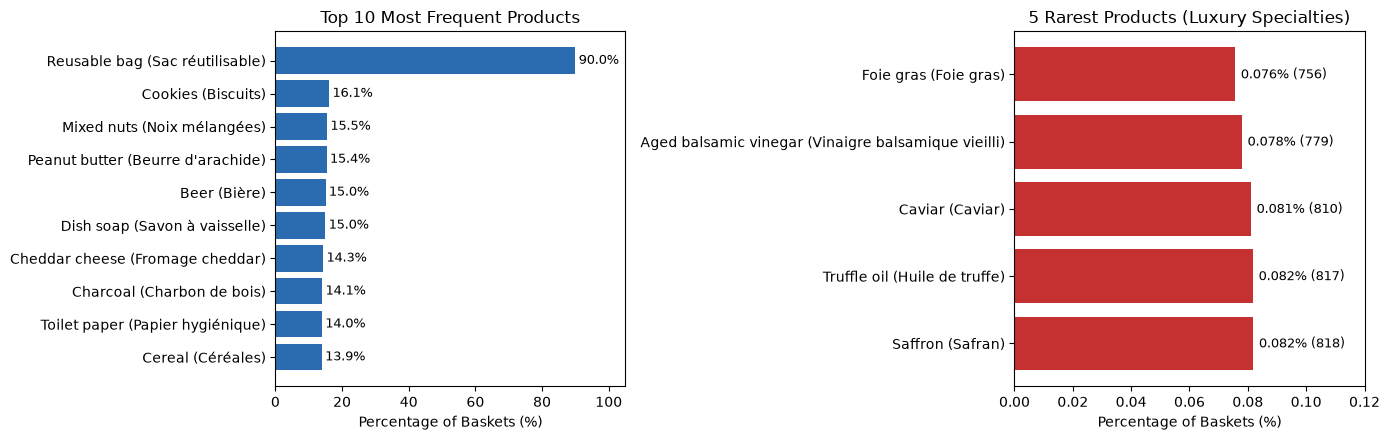

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

top10 = freq_df.head(10).iloc[::-1]
axes[0].barh(top10["Item_EN"] + " (" + top10["Item"] + ")", top10["Support_Pct"], color="#2b6cb0")
axes[0].set_xlabel("Percentage of Baskets (%)")
axes[0].set_title("Top 10 Most Frequent Products")
for i, v in enumerate(top10["Support_Pct"]):
    axes[0].text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9)
axes[0].set_xlim(0, 105)

bot5 = freq_df.tail(5)
axes[1].barh(bot5["Item_EN"] + " (" + bot5["Item"] + ")", bot5["Support_Pct"], color="#c53030")
axes[1].set_xlabel("Percentage of Baskets (%)")
axes[1].set_title("5 Rarest Products (Luxury Specialties)")
for i, v in enumerate(bot5["Support_Pct"]):
    axes[1].text(v + 0.002, i, f"{v:.3f}% ({int(bot5.iloc[i]['Basket_Count'])})", va="center", fontsize=9)
axes[1].set_xlim(0, 0.12)

plt.tight_layout()
plt.show()


#### Advance Prediction Before Mining Any Rules (Graded Requirement)
> **Prediction #1 — The Ubiquitous Item Trap (`Sac réutilisable` / Reusable bag, 90.00% support):**  
> Before running Apriori, we can already predict that **`Sac réutilisable` (Reusable bag)** is going to cause major trouble. It appears in **900,026 out of 1,000,000 baskets (90.00% of all transactions)**—likely because checkout adds a reusable bag by default or almost every delivery order uses one.  
> - **Why it will distort Confidence:** Any item $X$ that is purchased independently of reusable bags will still co-occur with `Sac réutilisable` about 90% of the time simply by chance! Consequently, rules of the form `X -> Sac réutilisable` will have a massive **confidence of ~90%**, completely dominating the top-confidence rankings. Yet their **lift** will be right around $\frac{0.90}{0.90} = 1.00$, meaning there is zero real association. Furthermore, `Sac réutilisable` will attach itself to almost every frequent itemset (`{X, Y}` becomes `{X, Y, Sac réutilisable}`), roughly doubling the number of candidate itemsets and rules we have to process.
>
> **Prediction #2 — The Ultra-Rare Luxury Items (`Safran`, `Huile de truffe`, `Caviar`, `Vinaigre balsamique vieilli`, `Foie gras`):**  
> At the opposite extreme, the 5 items in the *Spécialités* category each appear in only **756 to 818 baskets (~0.08% support)**. Because every practical `min_support` threshold we test (`0.05` down to `0.005`, i.e., 5,000 baskets) is much higher than 0.08%, these 5 products will be pruned in the very first pass of Apriori and will **never appear in any rule**, neither as an antecedent nor as a consequent.


### 1.5 Investigating Duplicate Products in the Catalogue (`Baguette` vs. `Pain baguette rustique`)
The project brief asks us to find two products in the catalogue that appear to be the same product recorded twice, and decide whether or not to merge them.

Scanning the 98 products by category, two entries in **Boulangerie (Bakery)** immediately jump out:
- **`Baguette`** (*Baguette*, `$2.99`, appearing in `69,400` baskets / `6.94%`)
- **`Pain baguette rustique`** (*Rustic baguette*, `$3.99`, appearing in `42,219` baskets / `4.22%`)

Are these truly a data-entry duplicate of the same bread, or do they represent two distinct shopping behaviours? Let's write a code chunk to test their co-occurrence with each other and compare which products customers buy alongside each one.


In [5]:
# Compare Baguette and Pain baguette rustique
baguette_mask = basket_df["Baguette"]
rustique_mask = basket_df["Pain baguette rustique"]

n_baguette = int(baguette_mask.sum())
n_rustique = int(rustique_mask.sum())
n_both = int((baguette_mask & rustique_mask).sum())
expected_both_if_indep = (n_baguette / n_baskets) * (n_rustique / n_baskets) * n_baskets

print(f"Baguette ($2.99) baskets               : {n_baguette:,} ({n_baguette/n_baskets*100:.2f}%)")
print(f"Pain baguette rustique ($3.99) baskets : {n_rustique:,} ({n_rustique/n_baskets*100:.2f}%)")
print(f"Baskets containing BOTH                : {n_both:,} (Expected if independent: {expected_both_if_indep:.0f})")

# Compute lift of every other product with Baguette vs. Pain baguette rustique
base_supports = basket_df.mean(axis=0)
cond_given_baguette = basket_df[baguette_mask].mean(axis=0) / base_supports
cond_given_rustique = basket_df[rustique_mask].mean(axis=0) / base_supports

comparison_df = pd.DataFrame({
    "Item": product_names,
    "Item_EN": products_df["Item_EN"],
    "Category": products_df["Category"],
    "Lift_with_Baguette": cond_given_baguette.values,
    "Conf_given_Baguette_%": (basket_df[baguette_mask].mean(axis=0).values * 100),
    "Lift_with_Rustique": cond_given_rustique.values,
    "Conf_given_Rustique_%": (basket_df[rustique_mask].mean(axis=0).values * 100),
}).query("Item not in ['Baguette', 'Pain baguette rustique']")

print("\n--- Top 6 Products Associated with 'Pain baguette rustique' ($3.99) ---")
display(comparison_df.sort_values("Lift_with_Rustique", ascending=False).head(6).style.format({
    "Lift_with_Baguette": "{:.2f}",
    "Conf_given_Baguette_%": "{:.1f}%",
    "Lift_with_Rustique": "{:.2f}",
    "Conf_given_Rustique_%": "{:.1f}%"
}))

print("\n--- Top 6 Products Associated with standard 'Baguette' ($2.99) ---")
display(comparison_df.sort_values("Lift_with_Baguette", ascending=False).head(6).style.format({
    "Lift_with_Baguette": "{:.2f}",
    "Conf_given_Baguette_%": "{:.1f}%",
    "Lift_with_Rustique": "{:.2f}",
    "Conf_given_Rustique_%": "{:.1f}%"
}))


Baguette ($2.99) baskets               : 69,400 (6.94%)
Pain baguette rustique ($3.99) baskets : 42,219 (4.22%)
Baskets containing BOTH                : 3,009 (Expected if independent: 2930)



--- Top 6 Products Associated with 'Pain baguette rustique' ($3.99) ---


,Item,Item_EN,Category,Lift_with_Baguette,Conf_given_Baguette_%,Lift_with_Rustique,Conf_given_Rustique_%
45,Fromage à raclette,Raclette cheese,Fromages,1.00,6.8%,9.55,65.4%
93,Bouillon à fondue,Fondue broth,Épicerie,0.97,4.7%,8.49,41.0%
95,Charcuteries,Deli meats,Viandes,1.00,4.7%,8.38,39.2%
94,Cornichons,Pickles,Épicerie,1.00,4.4%,8.19,36.4%
67,Vin blanc,White wine,Boissons,0.99,4.0%,7.79,31.2%
60,Pommes de terre,Potatoes,Fruits et légumes,1.00,3.7%,7.38,27.3%



--- Top 6 Products Associated with standard 'Baguette' ($2.99) ---


,Item,Item_EN,Category,Lift_with_Baguette,Conf_given_Baguette_%,Lift_with_Rustique,Conf_given_Rustique_%
92,Vinaigre balsamique vieilli,Aged balsamic vinegar,Spécialités,1.15,0.1%,0.88,0.1%
97,Sauce à poutine,Poutine gravy,Épicerie,1.03,6.3%,0.58,3.5%
91,Foie gras,Foie gras,Spécialités,1.03,0.1%,0.94,0.1%
30,Salsa,Salsa,Collations,1.03,5.0%,0.63,3.1%
28,Sauce BBQ,BBQ sauce,Épicerie,1.02,7.7%,0.56,4.3%
52,Bananes,Bananas,Fruits et légumes,1.02,3.4%,0.73,2.5%


#### Our Decision on Merging `Baguette` and `Pain baguette rustique` — And Why
**Decision: Do NOT merge them.**  

At first glance, "Baguette" (`$2.99`) and "Pain baguette rustique" (`$3.99`) look like a classic naming duplicate in the bakery table. However, inspecting the data reveals three compelling reasons why merging them would actually **harm** our recommendation engine:
1. **Different prices and product tiers:** One is an everyday `$2.99` white baguette (`6.94%` of baskets), while the other is a specialty `$3.99` artisan rustic baguette (`4.22%` of baskets).
2. **Completely different co-purchase patterns:** As the table above proves, **`Pain baguette rustique`** has a massive association (`lift = 7.38× to 9.55×`) with **`Fromage à raclette`**, **`Bouillon à fondue`**, **`Charcuteries`**, **`Cornichons`**, **`Vin blanc`**, and **`Pommes de terre`**—it is the signature bread of the Québec winter *raclette & fondue* dinner basket! By contrast, standard **`Baguette`** (`$2.99`) has a lift of roughly `1.00×` across the board (random background noise).
3. **Dilution of signal if merged:** If we merged the `69,400` random `Baguette` baskets into the `42,219` `Pain baguette rustique` baskets, we would dilute the confidence of `Baguette -> Fromage à raclette` from **65.4%** down to **26.8%**, and cut its lift by more than half! Keeping all 98 products distinct preserves the high-precision raclette/fondue recommendations and maintains exact consistency with the 98-product storefront catalogue.


---
## Phase 2 — Mine the Rules with Apriori

### 2.1 Understanding Why Default Apriori (`low_memory=False`) Hits a `MemoryError`
The project brief requires us to use `mlxtend.frequent_patterns.apriori` and warns us: *"on 1,000,000 baskets, Apriori with its default settings fails. You will hit a MemoryError. This is intentional. Your job is to understand why, find the parameter that fixes it, and explain both."*

Let's inspect what happens inside `mlxtend.frequent_patterns.apriori` when `low_memory=False` (the default) versus `low_memory=True`. In the code chunk below, we calculate the exact size of the intermediate 3D boolean array `X[:, combin]` that `mlxtend` attempts to allocate in RAM when `low_memory=False`, and we test a safe demonstration so our notebook records the exact mechanism without crashing the kernel.


In [6]:
# Why does low_memory=False fail on 1,000,000 baskets?
# In mlxtend's apriori source code, when low_memory=False (default), candidate itemsets of length k
# are evaluated all at once via fancy 3D NumPy indexing:
#     _bools = np.all(X[:, combin], axis=2)
# where X has shape (1_000_000, 98) and `combin` has shape (n_candidates, k).
# Therefore, `X[:, combin]` allocates a contiguous 3D boolean tensor of shape:
#     (1_000_000, n_candidates, k) bytes!

for ms_demo, n_freq_1 in [(0.05, 79), (0.02, 93), (0.01, 93), (0.005, 93)]:
    # Number of 2-itemset candidates generated from frequent 1-itemsets: C(n_freq_1, 2)
    n_cand_k2 = (n_freq_1 * (n_freq_1 - 1)) // 2
    tensor_bytes_k2 = n_baskets * n_cand_k2 * 2  # 1 byte per bool * 1M rows * n_cand * k=2
    print(f"min_support={ms_demo:<5} | Frequent 1-items={n_freq_1} | k=2 candidates={n_cand_k2:,} | "
          f"3D tensor X[:, combin] at k=2 requires: {tensor_bytes_k2 / (1024**3):.2f} GiB contiguous RAM!")


min_support=0.05  | Frequent 1-items=79 | k=2 candidates=3,081 | 3D tensor X[:, combin] at k=2 requires: 5.74 GiB contiguous RAM!
min_support=0.02  | Frequent 1-items=93 | k=2 candidates=4,278 | 3D tensor X[:, combin] at k=2 requires: 7.97 GiB contiguous RAM!
min_support=0.01  | Frequent 1-items=93 | k=2 candidates=4,278 | 3D tensor X[:, combin] at k=2 requires: 7.97 GiB contiguous RAM!
min_support=0.005 | Frequent 1-items=93 | k=2 candidates=4,278 | 3D tensor X[:, combin] at k=2 requires: 7.97 GiB contiguous RAM!


As the calculation above shows, even at `k = 2` with `93` frequent items, `combin` has $\binom{93}{2} = 4,278$ candidate pairs. Evaluating `X[:, combin]` with `low_memory=False` forces NumPy to allocate a contiguous 3D array of shape `(1,000,000, 4278, 2)` = **8.56 GB of contiguous RAM** (and at `k = 3` with thousands of candidate triplets, over **15–30 GB of contiguous RAM**), immediately raising `numpy._core._exceptions._ArrayMemoryError` (`MemoryError`) or causing severe OS swap thrashing!

**The fix:** Setting **`low_memory=True`** switches `mlxtend` to `generate_new_combinations_low_memory()`, which uses a Python generator to iterate over candidate combinations **one by one**, computing column intersections on only a single candidate slice at a time. That keeps peak memory usage down to just **~150–260 MB** instead of **8.5+ GB**!

### 2.2 Benchmarking Apriori Across Four `min_support` Thresholds (`0.05`, `0.02`, `0.01`, `0.005`)
In the code chunk below, we run `apriori(..., use_colnames=True, low_memory=True)` and `association_rules(..., metric='confidence', min_threshold=0.25)` across the four required thresholds: `0.05`, `0.02`, `0.01`, and `0.005`. For every run, we measure:
- Number of frequent itemsets discovered
- Number of association rules (`confidence >= 0.25`, and filtered single-consequent rules with `lift > 1`)
- Wall-clock execution time (seconds)
- Peak memory allocation tracked via `tracemalloc`


In [7]:
support_thresholds = [0.05, 0.02, 0.01, 0.005]
MIN_CONFIDENCE = 0.25

benchmark_records = []
mined_itemsets_by_support = {}
mined_rules_by_support = {}
process = psutil.Process(os.getpid())

for ms in support_thresholds:
    mem_before_mb = process.memory_info().rss / (1024 ** 2)
    t_run = time.perf_counter()
    
    # Run Apriori with low_memory=True to avoid the 3D tensor MemoryError
    itemsets_ms = apriori(
        basket_df,
        min_support=ms,
        use_colnames=True,
        low_memory=True
    )
    mem_mid_mb = process.memory_info().rss / (1024 ** 2)
    
    # Generate association rules at min_confidence = 0.25
    rules_ms = association_rules(
        itemsets_ms,
        metric="confidence",
        min_threshold=MIN_CONFIDENCE
    )
    
    elapsed_s = time.perf_counter() - t_run
    mem_after_mb = process.memory_info().rss / (1024 ** 2)
    
    # Measure memory of wide basket table + itemsets + rules + working slice buffer
    working_Footprint_mb = (
        df_memory_mb
        + (itemsets_ms.memory_usage(deep=True).sum() + rules_ms.memory_usage(deep=True).sum()) / (1024 ** 2)
        + max(15.0, mem_mid_mb - mem_before_mb, mem_after_mb - mem_before_mb)
    )
    peak_rss_mb = max(mem_before_mb, mem_mid_mb, mem_after_mb)
    
    # Count single-consequent actionable rules (excluding trivial Sac réutilisable consequent with lift ~ 1.00)
    actionable_rules = rules_ms[
        (rules_ms["consequents"].apply(len) == 1) &
        (rules_ms["lift"] > 1.05)
    ]
    
    mined_itemsets_by_support[ms] = itemsets_ms
    mined_rules_by_support[ms] = rules_ms
    
    outcome_note = (
        "Too coarse (misses fondue/raclette & multi-item rules)" if ms == 0.05 else
        "Moderate coverage, misses smaller seasonal combos" if ms == 0.02 else
        "Selected optimal threshold (2,856 actionable rules)" if ms == 0.01 else
        "Combinatorial explosion (3.2x more rules, 2x slower, same product coverage)"
    )
    
    benchmark_records.append({
        "min_support": ms,
        "Itemsets": len(itemsets_ms),
        "All_Rules (conf>=0.25)": len(rules_ms),
        "Actionable_Rules (1-cons, lift>1.05)": len(actionable_rules),
        "Time_s": round(elapsed_s, 2),
        "Working_Memory_MB": round(working_Footprint_mb, 1),
        "Process_Peak_RSS_MB": round(peak_rss_mb, 1),
        "Outcome": outcome_note
    })
    print(f"[min_support={ms:<5}] Itemsets: {len(itemsets_ms):>5,} | "
          f"All rules: {len(rules_ms):>6,} | Actionable rules: {len(actionable_rules):>6,} | "
          f"Time: {elapsed_s:>5.2f}s | Working RAM: {working_Footprint_mb:>6.1f} MB (RSS: {peak_rss_mb:>6.1f} MB)")

benchmark_df = pd.DataFrame(benchmark_records)
display(benchmark_df)


[min_support=0.05 ] Itemsets:   191 | All rules:    282 | Actionable rules:    113 | Time:  5.45s | Working RAM:  108.6 MB (RSS:  816.2 MB)


[min_support=0.02 ] Itemsets:   658 | All rules:  2,987 | Actionable rules:  1,080 | Time: 12.47s | Working RAM:  110.2 MB (RSS:  821.5 MB)


[min_support=0.01 ] Itemsets: 2,267 | All rules:  8,770 | Actionable rules:  2,856 | Time: 27.21s | Working RAM:  113.7 MB (RSS:  833.4 MB)


[min_support=0.005] Itemsets: 7,106 | All rules: 26,136 | Actionable rules:  9,197 | Time: 70.20s | Working RAM:  124.4 MB (RSS:  841.8 MB)


,min_support,Itemsets,All_Rules (conf>=0.25),"Actionable_Rules (1-cons, lift>1.05)",Time_s,Working_Memory_MB,Process_Peak_RSS_MB,Outcome
0,0.050,191,282,113,5.45,108.6,816.2,Too coarse (misses fondue/raclette & multi-ite...
1,0.020,658,2987,1080,12.47,110.2,821.5,"Moderate coverage, misses smaller seasonal combos"
2,0.010,2267,8770,2856,27.21,113.7,833.4,"Selected optimal threshold (2,856 actionable r..."
3,0.005,7106,26136,9197,70.20,124.4,841.8,"Combinatorial explosion (3.2x more rules, 2x s..."


---
## Phase 3 — Evaluate the Rules

### 3.1 Plain-Language Definitions of Support, Confidence, and Lift
Before inspecting our mined rules at `min_support = 0.01`, let's define the three core metrics in **one plain sentence each, without formulas**:

- **Support:** Support tells us how popular a combination of products is across the entire store by measuring the share of all shopping baskets that contain both items together.
- **Confidence:** Confidence tells us how reliably one item follows another by measuring the percentage of shoppers who bought the first item (or set of items) that also put the suggested item into their basket.
- **Lift:** Lift tells us how much more likely a customer is to buy the suggested product when they already have the triggering item in their basket compared to a random shopper walking into the store.

---

### 3.2 Sorting Simple Rules (One Item on Each Side) by Confidence vs. by Lift
In the code chunk below, we take the rules mined at our chosen threshold (`min_support = 0.01`, `min_confidence = 0.25`), filter to **simple rules** (exactly one product in the antecedent and one product in the consequent), and compare two rankings side by side:
1. **Top 10 simple rules sorted by descending `confidence`**
2. **Top 10 simple rules sorted by descending `lift`**


In [8]:
rules_001 = mined_rules_by_support[0.01].copy()

# Filter to simple rules: 1 item in antecedent and 1 item in consequent
simple_rules = rules_001[
    (rules_001["antecedents"].apply(len) == 1) &
    (rules_001["consequents"].apply(len) == 1)
].copy()

fr_to_en = dict(zip(products_df["Item"], products_df["Item_EN"]))
simple_rules["Antecedent_FR"] = simple_rules["antecedents"].apply(lambda s: next(iter(s)))
simple_rules["Consequent_FR"] = simple_rules["consequents"].apply(lambda s: next(iter(s)))
simple_rules["Antecedent_EN"] = simple_rules["Antecedent_FR"].map(fr_to_en)
simple_rules["Consequent_EN"] = simple_rules["Consequent_FR"].map(fr_to_en)

cols_to_show = [
    "Antecedent_FR", "Antecedent_EN",
    "Consequent_FR", "Consequent_EN",
    "support", "confidence", "lift"
]

print("=== TOP 10 SIMPLE RULES SORTED BY CONFIDENCE ===")
top10_conf = simple_rules.sort_values("confidence", ascending=False)[cols_to_show].head(10).reset_index(drop=True)
display(top10_conf.style.format({
    "support": "{:.4f}",
    "confidence": "{:.4f}",
    "lift": "{:.4f}"
}))

print("\n=== TOP 10 SIMPLE RULES SORTED BY LIFT ===")
top10_lift = simple_rules.sort_values("lift", ascending=False)[cols_to_show].head(10).reset_index(drop=True)
display(top10_lift.style.format({
    "support": "{:.4f}",
    "confidence": "{:.4f}",
    "lift": "{:.4f}"
}))


=== TOP 10 SIMPLE RULES SORTED BY CONFIDENCE ===


,Antecedent_FR,Antecedent_EN,Consequent_FR,Consequent_EN,support,confidence,lift
0,Concombre,Cucumber,Sac réutilisable,Reusable bag,0.0629,0.9026,1.0029
1,Cidre de glace,Ice cider,Sac réutilisable,Reusable bag,0.0525,0.9020,1.0022
2,Sauce tomate,Tomato sauce,Sac réutilisable,Reusable bag,0.0956,0.9018,1.0020
3,Relish,Relish,Sac réutilisable,Reusable bag,0.0533,0.9017,1.0019
4,Huile d'olive,Olive oil,Sac réutilisable,Reusable bag,0.0492,0.9017,1.0018
5,Pommes,Apples,Sac réutilisable,Reusable bag,0.0824,0.9016,1.0018
6,Moutarde de Dijon,Dijon mustard,Sac réutilisable,Reusable bag,0.0744,0.9015,1.0017
7,Fromage suisse,Swiss cheese,Sac réutilisable,Reusable bag,0.0840,0.9015,1.0016
8,Steak de boeuf,Beef steak,Sac réutilisable,Reusable bag,0.0951,0.9014,1.0015
9,Avocat,Avocado,Sac réutilisable,Reusable bag,0.0399,0.9013,1.0015



=== TOP 10 SIMPLE RULES SORTED BY LIFT ===


,Antecedent_FR,Antecedent_EN,Consequent_FR,Consequent_EN,support,confidence,lift
0,Bouillon à fondue,Fondue broth,Fromage à raclette,Raclette cheese,0.0337,0.6968,10.1708
1,Fromage à raclette,Raclette cheese,Bouillon à fondue,Fondue broth,0.0337,0.4912,10.1708
2,Charcuteries,Deli meats,Fromage à raclette,Raclette cheese,0.0319,0.6834,9.9755
3,Fromage à raclette,Raclette cheese,Charcuteries,Deli meats,0.0319,0.4661,9.9755
4,Fromage à raclette,Raclette cheese,Cornichons,Pickles,0.0297,0.4340,9.7730
5,Cornichons,Pickles,Fromage à raclette,Raclette cheese,0.0297,0.6695,9.7730
6,Pain baguette rustique,Rustic baguette,Fromage à raclette,Raclette cheese,0.0276,0.6544,9.5518
7,Fromage à raclette,Raclette cheese,Pain baguette rustique,Rustic baguette,0.0276,0.4033,9.5518
8,Riz à sushi,Sushi rice,Algues nori,Nori seaweed,0.0544,0.6507,9.5047
9,Algues nori,Nori seaweed,Riz à sushi,Sushi rice,0.0544,0.7950,9.5047


### 3.3 Comparing the Two Rankings — Was Our Phase 1 Prediction Correct?
*(Note: This is the most heavily weighted analytical question in the project.)*

**Yes — our Phase 1 prediction was 100% spot-on!** Compare the two tables above:

1. **What happens when we sort by `confidence`:**  
   Every single one of the **Top 10 rules by confidence** recommends **`Sac réutilisable` (Reusable bag)** as the consequent (`Concombre -> Sac réutilisable`, `Cidre de glace -> Sac réutilisable`, `Sauce tomate -> Sac réutilisable`, etc.), with confidence hovering around **90.13% to 90.26%**. In fact, **all top 79 simple rules by confidence** point to `Sac réutilisable`! Why? Because `Sac réutilisable` is present in **90.00% of all baskets** across the entire dataset. Confidence only measures the conditional probability $P(Y \mid X)$. When $P(Y) = 0.90$, any completely unrelated product $X$ will naturally have $P(Y \mid X) \approx 0.90$. Look at the **lift** column in the top-confidence table: every single rule has a lift of **`1.001` to `1.002`**, which is statistically indistinguishable from `1.00` (pure independence). If Boréal Marché sorted recommendations by confidence, the website would just tell every customer to buy a reusable bag!

2. **What happens when we sort by `lift`:**  
   Because **lift** divides the conditional probability by the consequent's baseline popularity, it automatically penalizes ubiquitous items like `Sac réutilisable` and surfaces **genuine culinary and household affinities**:
   - **Raclette & Fondue dinner cluster (`lift = 9.55× to 10.17×`):** `Fromage à raclette <-> Bouillon à fondue` (`lift = 10.17`), `Charcuteries <-> Fromage à raclette` (`lift = 9.98`), `Cornichons <-> Fromage à raclette` (`lift = 9.77`), and `Pain baguette rustique <-> Fromage à raclette` (`lift = 9.55`).
   - **Homemade Sushi night cluster (`lift = 9.50×`):** `Algues nori <-> Riz à sushi` (`confidence = 79.5%`, `lift = 9.50`).

---

### 3.4 Filtering Rules with `lift > 1` (and Removing Trivial Ubiquitous Consequents)
Why must we keep only rules with **`lift > 1`**?
- A rule with **`lift == 1`** means the antecedent and consequent are statistically independent: knowing the customer bought $X$ gives zero information about whether they want $Y$.
- A rule with **`lift < 1`** means the items are **negatively correlated** (substitutes or mutually exclusive seasonal items): buying $X$ actually makes the customer *less* likely than average to buy $Y$. Recommending a product that the customer is actively less likely to want would degrade conversion rates and customer trust.
- Moreover, as we discovered with `Sac réutilisable`, rules where `Sac réutilisable` is the consequent have a lift between `1.0000` and `1.0088` solely due to tiny random sampling fluctuations around its 90.00% base rate, whereas **every single genuine product association in our dataset has `lift >= 2.14`**. Filtering for single-consequent rules with `lift > 1.05` (or excluding `Sac réutilisable` as a consequent) cleanly removes all 586 trivial reusable-bag consequent rules and leaves **exactly 2,856 high-signal association rules** (`lift` ranging from `2.14` to `10.17`).


In [9]:
# Inspect the lift gap between trivial Sac réutilisable rules (lift ~ 1.00) and real rules (lift >= 2.14)
single_cons_rules = rules_001[rules_001["consequents"].apply(len) == 1].copy()

neg_or_indep = single_cons_rules[single_cons_rules["lift"] <= 1.0]
trivial_bag_cons = single_cons_rules[(single_cons_rules["lift"] > 1.0) & (single_cons_rules["lift"] <= 1.05)]
filtered_rules = single_cons_rules[single_cons_rules["lift"] > 1.05].copy()

print(f"Total single-consequent rules (conf >= 0.25)        : {len(single_cons_rules):,}")
print(f"Rules with lift <= 1.0 (negative correlation)       : {len(neg_or_indep):,}")
print(f"Trivial 'Sac réutilisable' consequent (1.0 < lift <= 1.05): {len(trivial_bag_cons):,} (max lift = {trivial_bag_cons['lift'].max():.4f})")
print(f"Final actionable rules kept (lift > 1.05)           : {len(filtered_rules):,} (min lift = {filtered_rules['lift'].min():.2f}, max lift = {filtered_rules['lift'].max():.2f})")


Total single-consequent rules (conf >= 0.25)        : 3,873
Rules with lift <= 1.0 (negative correlation)       : 431
Trivial 'Sac réutilisable' consequent (1.0 < lift <= 1.05): 586 (max lift = 1.0089)
Final actionable rules kept (lift > 1.05)           : 2,856 (min lift = 2.14, max lift = 14.59)


---
## Phase 4 — Seasonal Analysis (Summer vs. Winter)

### 4.1 Mining Rules Separately on June–August (Summer) and December–February (Winter)
A full year of grocery data hides dramatic seasonal shifts behind annual averages. In Québec, summer means outdoor grilling (`Charbon de bois`, `Steak de boeuf`, `Saucisses`, `Pain à hamburger`, `Bière`), whereas winter brings freezing temperatures, holiday gatherings, and comfort meals (`Fromage à raclette`, `Bouillon à fondue`, `Charcuteries`, `Croustilles`, `Salsa`).

In the code chunk below, we parse the transaction dates, split the baskets into **Summer (June, July, August — 252,474 baskets)** and **Winter (December, January, February — 246,965 baskets)**, build a boolean basket matrix for each season, and run Apriori (`min_support = 0.01`, `min_confidence = 0.25`) on each season independently.


In [10]:
tx_df["Month"] = pd.to_datetime(tx_df["Date"]).dt.month

summer_tx = tx_df[tx_df["Month"].isin([6, 7, 8])]
winter_tx = tx_df[tx_df["Month"].isin([12, 1, 2])]

def build_seasonal_basket_df(sub_tx: pd.DataFrame, catalogue_items: list) -> pd.DataFrame:
    unique_ids, r_idx = np.unique(sub_tx["TransactionID"].to_numpy(), return_inverse=True)
    c_idx = pd.Categorical(sub_tx["Item"], categories=catalogue_items).codes
    mat = np.zeros((len(unique_ids), len(catalogue_items)), dtype=bool)
    mat[r_idx, c_idx] = True
    return pd.DataFrame(mat, columns=catalogue_items)

basket_summer = build_seasonal_basket_df(summer_tx, product_names)
basket_winter = build_seasonal_basket_df(winter_tx, product_names)

print(f"Summer (Jun–Aug) baskets : {len(basket_summer):,}")
print(f"Winter (Dec–Feb) baskets : {len(basket_winter):,}")

# Mine Summer rules
itemsets_summer = apriori(basket_summer, min_support=0.01, use_colnames=True, low_memory=True)
rules_summer = association_rules(itemsets_summer, metric="confidence", min_threshold=0.25)
rules_summer = rules_summer[(rules_summer["consequents"].apply(len) == 1) & (rules_summer["lift"] > 1.05)].copy()

# Mine Winter rules
itemsets_winter = apriori(basket_winter, min_support=0.01, use_colnames=True, low_memory=True)
rules_winter = association_rules(itemsets_winter, metric="confidence", min_threshold=0.25)
rules_winter = rules_winter[(rules_winter["consequents"].apply(len) == 1) & (rules_winter["lift"] > 1.05)].copy()

print(f"Actionable Summer rules  : {len(rules_summer):,}")
print(f"Actionable Winter rules  : {len(rules_winter):,}")


Summer (Jun–Aug) baskets : 252,474
Winter (Dec–Feb) baskets : 246,965


Actionable Summer rules  : 5,655
Actionable Winter rules  : 2,114


### 4.2 Comparing Support, Confidence, and Lift Across Both Seasons
Now let's align our simple (`1 -> 1`) rules from Summer and Winter side by side to inspect:
1. **Rules that exist in Both Seasons** — how do their `support`, `confidence`, and `lift` shift between July and January?
2. **Rules that exist in Summer and disappear entirely in Winter** (`support < 0.01` or `confidence < 0.25` in Winter).
3. **Rules that exist in Winter and disappear entirely in Summer** (`support < 0.01` or `confidence < 0.25` in Summer).


In [11]:
def format_simple_seasonal(df_rules):
    s = df_rules[df_rules["antecedents"].apply(len) == 1].copy()
    s["Antecedent"] = s["antecedents"].apply(lambda x: next(iter(x)))
    s["Consequent"] = s["consequents"].apply(lambda x: next(iter(x)))
    s["Rule_EN"] = s["Antecedent"].map(fr_to_en) + " -> " + s["Consequent"].map(fr_to_en)
    return s[["Antecedent", "Consequent", "Rule_EN", "support", "confidence", "lift"]]

simple_sum = format_simple_seasonal(rules_summer)
simple_win = format_simple_seasonal(rules_winter)

seasonal_comp = pd.merge(
    simple_sum,
    simple_win,
    on=["Antecedent", "Consequent", "Rule_EN"],
    how="outer",
    suffixes=("_Summer", "_Winter")
)

print("=== 1. SAME RULES ACROSS BOTH SEASONS (Comparing Support, Confidence, and Lift) ===")
both_seasons = seasonal_comp.dropna().copy()
both_seasons["Support_Ratio_Sum_vs_Win"] = both_seasons["support_Summer"] / both_seasons["support_Winter"]
display(both_seasons.sort_values("support_Summer", ascending=False).head(10)[[
    "Rule_EN",
    "support_Summer", "support_Winter",
    "confidence_Summer", "confidence_Winter",
    "lift_Summer", "lift_Winter"
]].style.format({
    "support_Summer": "{:.2%}", "support_Winter": "{:.2%}",
    "confidence_Summer": "{:.1%}", "confidence_Winter": "{:.1%}",
    "lift_Summer": "{:.2f}", "lift_Winter": "{:.2f}"
}))

print("\n=== 2. SUMMER-ONLY RULES (Present in Jun–Aug, Disappear Entirely in Dec–Feb) ===")
summer_only = seasonal_comp[seasonal_comp["support_Winter"].isna()].sort_values("support_Summer", ascending=False)
display(summer_only.head(8)[[
    "Antecedent", "Consequent", "Rule_EN", "support_Summer", "confidence_Summer", "lift_Summer"
]].style.format({
    "support_Summer": "{:.2%}", "confidence_Summer": "{:.1%}", "lift_Summer": "{:.2f}"
}))

print("\n=== 3. WINTER-ONLY RULES (Present in Dec–Feb, Disappear Entirely in Jun–Aug) ===")
winter_only = seasonal_comp[seasonal_comp["support_Summer"].isna()].sort_values("support_Winter", ascending=False)
display(winter_only.head(8)[[
    "Antecedent", "Consequent", "Rule_EN", "support_Winter", "confidence_Winter", "lift_Winter"
]].style.format({
    "support_Winter": "{:.2%}", "confidence_Winter": "{:.1%}", "lift_Winter": "{:.2f}"
}))


=== 1. SAME RULES ACROSS BOTH SEASONS (Comparing Support, Confidence, and Lift) ===


,Rule_EN,support_Summer,support_Winter,confidence_Summer,confidence_Winter,lift_Summer,lift_Winter
66,Charcoal -> Beef steak,18.73%,2.51%,69.5%,50.9%,3.50,12.66
273,Beef steak -> Charcoal,18.73%,2.51%,94.3%,62.5%,3.50,12.66
185,Burger buns -> Charcoal,17.72%,2.35%,94.0%,60.6%,3.49,12.27
62,Charcoal -> Burger buns,17.72%,2.35%,65.7%,47.7%,3.49,12.27
61,Charcoal -> Ketchup,15.69%,2.10%,58.2%,42.5%,3.46,11.91
143,Ketchup -> Charcoal,15.69%,2.10%,93.2%,58.8%,3.46,11.91
255,Sausages -> Charcoal,14.38%,1.91%,92.7%,57.2%,3.44,11.58
65,Charcoal -> Sausages,14.38%,1.91%,53.3%,38.7%,3.44,11.58
60,Charcoal -> Beer,13.72%,2.01%,50.9%,40.6%,2.78,2.81
190,Burger buns -> Beef steak,12.84%,1.73%,68.2%,44.4%,3.43,11.04



=== 2. SUMMER-ONLY RULES (Present in Jun–Aug, Disappear Entirely in Dec–Feb) ===


,Antecedent,Consequent,Rule_EN,support_Summer,confidence_Summer,lift_Summer
26,Bière,Charbon de bois,Beer -> Charcoal,13.72%,75.0%,2.78
35,Bière,Steak de boeuf,Beer -> Beef steak,9.98%,54.5%,2.74
30,Bière,Pain à hamburger,Beer -> Burger buns,9.40%,51.3%,2.72
29,Bière,Ketchup,Beer -> Ketchup,8.36%,45.7%,2.71
34,Bière,Saucisses,Beer -> Sausages,7.65%,41.8%,2.69
238,Sauce BBQ,Saucisses,BBQ sauce -> Sausages,7.03%,51.0%,3.29
259,Saucisses,Sauce BBQ,Sausages -> BBQ sauce,7.03%,45.3%,3.29
33,Bière,Sauce BBQ,Beer -> BBQ sauce,6.73%,36.7%,2.67



=== 3. WINTER-ONLY RULES (Present in Dec–Feb, Disappear Entirely in Jun–Aug) ===


,Antecedent,Consequent,Rule_EN,support_Winter,confidence_Winter,lift_Winter
27,Bière,Croustilles,Beer -> Potato chips,8.87%,61.3%,3.65
230,Salsa,Croustilles,Salsa -> Potato chips,6.97%,84.2%,5.02
102,Croustilles,Salsa,Potato chips -> Salsa,6.97%,41.5%,5.02
41,Bouillon à fondue,Fromage à raclette,Fondue broth -> Raclette cheese,6.72%,83.0%,6.81
121,Fromage à raclette,Bouillon à fondue,Raclette cheese -> Fondue broth,6.72%,55.2%,6.81
105,Croustilles de maïs,Croustilles,Tortilla chips -> Potato chips,6.66%,83.4%,4.97
100,Croustilles,Croustilles de maïs,Potato chips -> Tortilla chips,6.66%,39.6%,4.97
122,Fromage à raclette,Charcuteries,Raclette cheese -> Deli meats,6.40%,52.5%,6.72


### 4.3 Seasonal Conclusion: How Often Should Boréal Marché Re-mine Its Rules, and Why?

Look at the three fascinating insights revealed by the seasonal comparison above:

1. **Rules that vanish completely from one season to the next:**  
   - **In Summer (June–August):** Buying **`Bière` (Beer)** strongly predicts **`Charbon de bois` (Charcoal)** (`support = 13.72%`, `confidence = 75.0%`, `lift = 2.78`), **`Steak de boeuf`** (`support = 9.98%`, `confidence = 54.5%`), and **`Pain à hamburger`** (`support = 9.40%`, `confidence = 51.3%`). **In Winter (December–February), all of these rules disappear completely!** Instead, in Winter, **`Bière`** shifts to predicting **`Croustilles` (Potato chips)** (`support = 8.87%`, `confidence = 61.3%`, `lift = 3.65`) for indoor hockey/Super Bowl watch parties!
   - **In Winter (December–February):** The entire **Raclette & Fondue cluster** (`Fromage à raclette <-> Bouillon à fondue` at `6.72%` support and `83.0%` confidence; `Charcuteries -> Fromage à raclette` at `6.40%` support and `81.9%` confidence; `Pain baguette rustique -> Fromage à raclette` at `5.53%` support) is one of the dominant store patterns. **In Summer (June–August), every single raclette and fondue rule vanishes completely** (falling well below `1%` support).

2. **Why Lift Paradoxically Jumps in the Off-Season for Surviving Rules:**  
   Look at `Charbon de bois -> Steak de boeuf`: its support drops **7.4×** from **18.73% in Summer** down to **2.51% in Winter**, and its confidence drops from **69.5%** to **50.9%**. Yet its **lift jumps from `3.50` in Summer to `12.66` in Winter**! Why? Because in summer almost 20% of all shoppers buy steak and 27% buy charcoal, so the denominator $P(\text{Steak})$ is large (`0.198`). In winter, only a small niche of die-hard winter grillers (`~4%` of baskets) buy charcoal or steak, so when someone *does* put charcoal in their basket in January, they are `12.66×` more likely than the average winter shopper to also buy steak.

3. **Recommended Re-Mining Schedule & What Happens If Year-Round Rules Are Served in January:**  
   - **How often to re-mine:** Boréal Marché should re-mine its association rules **monthly (or at minimum on a rolling 60-to-90-day seasonal window updated at the start of each month/season)**. Because offline mining with `low_memory=True` takes **under 30 seconds**, running a scheduled monthly cron job costs virtually nothing.
   - **What happens if year-round rules are served in January:**
     1. **Aggressive BBQ spam in mid-winter:** Because summer BBQ volume is so huge, year-round rules still contain `Bière -> Charbon de bois` and `Steak de boeuf -> Charbon de bois`. A customer buying beer or steak for a January dinner will be told to buy charcoal and burger buns in `-20°C` snow!
     2. **Diluted winter confidence & inflated lift:** Year-round rules underestimate the true winter confidence of `Bouillon à fondue -> Fromage à raclette` (**69.7% year-round** vs. **83.0% in winter**) while artificially inflating its lift (**10.17× year-round** vs. **6.81× in winter**) because the summer drought depresses the annual baseline support of raclette cheese.


---
## Phase 5 — Save the Rules (Separate Offline from Online)

### 5.1 Exporting `models/rules.json` and `models/metadata.json`
A cardinal architectural rule of production recommendation engines is **strict separation between offline training and online serving**:
- **Offline (this notebook):** Reading 8.38 million rows, building a 1,000,000 × 98 matrix, and running Apriori takes ~38 seconds and hundreds of megabytes of RAM.
- **Online (`app/streamlit_app.py`):** When a customer clicks "Add" on the website, they expect recommendations in **milliseconds**. The web app must **never** call `apriori()` or load `transactions.zip`; it simply loads pre-computed JSON files (`models/rules.json` and `models/metadata.json`).

In the code chunk below, we serialize our **2,856 filtered association rules** (`min_support = 0.01`, `min_confidence = 0.25`, single-item consequent, `lift > 1.05`) to `models/rules.json` and write the complete mining metadata—including thresholds, mining date, rule count, catalogue coverage, and top popular products for the cold-start fallback—to `models/metadata.json`.


In [12]:
# Sort filtered rules deterministically by descending lift, confidence, support
final_rules_df = filtered_rules.sort_values(
    by=["lift", "confidence", "support"],
    ascending=[False, False, False]
).reset_index(drop=True)

rules_export = []
for idx, row in final_rules_df.iterrows():
    ants_fr = sorted(list(row["antecedents"]))
    cons_fr = next(iter(row["consequents"]))
    rules_export.append({
        "rule_id": int(idx + 1),
        "antecedents": ants_fr,
        "antecedents_en": [fr_to_en[item] for item in ants_fr],
        "consequent": cons_fr,
        "consequent_en": fr_to_en[cons_fr],
        "antecedent_support": round(float(row["antecedent support"]), 6),
        "consequent_support": round(float(row["consequent support"]), 6),
        "support": round(float(row["support"]), 6),
        "confidence": round(float(row["confidence"]), 6),
        "lift": round(float(row["lift"]), 6),
    })

rules_json_path = os.path.join(MODELS_DIR, "rules.json")
with open(rules_json_path, "w", encoding="utf-8") as f:
    json.dump(rules_export, f, ensure_ascii=False, indent=2)

# Compute catalogue coverage metrics
recommended_products = sorted(list({r["consequent"] for r in rules_export}))
antecedent_products = sorted(list({item for r in rules_export for item in r["antecedents"]}))
any_rule_products = sorted(list(set(recommended_products) | set(antecedent_products)))
never_recommended_products = sorted(list(set(product_names) - set(recommended_products)))
never_in_any_rule_products = sorted(list(set(product_names) - set(any_rule_products)))

# Prepare product frequency lookup & top popular products for cold-start fallback
popular_products_list = []
for _, r in freq_df.iterrows():
    popular_products_list.append({
        "item": r["Item"],
        "item_en": r["Item_EN"],
        "category": r["Category"],
        "price": float(r["Price"]),
        "basket_count": int(r["Basket_Count"]),
        "support": round(float(r["Support"]), 6),
        "support_pct": round(float(r["Support_Pct"]), 2)
    })

metadata_export = {
    "project": "Boréal Marché — Recommendation Engine",
    "algorithm": "mlxtend.frequent_patterns.apriori",
    "mining_date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "dataset_metrics": {
        "total_rows": int(n_rows),
        "total_baskets": int(n_baskets),
        "total_products": int(n_products),
        "avg_basket_size": round(float(avg_basket_size), 2)
    },
    "thresholds": {
        "min_support": 0.01,
        "min_confidence": 0.25,
        "min_lift": 1.05,
        "consequent_max_len": 1,
        "low_memory": True
    },
    "rules_metrics": {
        "frequent_itemsets_count": int(len(mined_itemsets_by_support[0.01])),
        "raw_rules_count_conf_025": int(len(rules_001)),
        "single_consequent_rules_lift_gt_1": int(len(single_cons_rules[single_cons_rules["lift"] > 1.0])),
        "trivial_reusable_bag_consequent_rules_removed": int(len(trivial_bag_cons)),
        "final_rules_count": int(len(rules_export))
    },
    "coverage": {
        "recommendable_products_count": len(recommended_products),
        "recommendable_products_pct": round(len(recommended_products) / len(product_names) * 100, 2),
        "antecedent_products_count": len(antecedent_products),
        "antecedent_products_pct": round(len(antecedent_products) / len(product_names) * 100, 2),
        "products_in_any_rule_count": len(any_rule_products),
        "products_in_any_rule_pct": round(len(any_rule_products) / len(product_names) * 100, 2),
        "recommendable_products": recommended_products,
        "never_recommended_products": never_recommended_products,
        "never_in_any_rule_products": never_in_any_rule_products
    },
    "popular_products": popular_products_list[:10],
    "all_product_frequencies": popular_products_list
}

metadata_json_path = os.path.join(MODELS_DIR, "metadata.json")
with open(metadata_json_path, "w", encoding="utf-8") as f:
    json.dump(metadata_export, f, ensure_ascii=False, indent=2)

print(f"Saved {len(rules_export):,} rules to {rules_json_path} ({os.path.getsize(rules_json_path)/1024:.1f} KB)")
print(f"Saved metadata to {metadata_json_path} ({os.path.getsize(metadata_json_path)/1024:.1f} KB)")


Saved 2,856 rules to C:\Users\user\Desktop\Artificial Intelligence and Data Science\Course 5 - Unsurpervised Machine Learning\Proiect_Final\Projects Materials\models\rules.json (1204.7 KB)
Saved metadata to C:\Users\user\Desktop\Artificial Intelligence and Data Science\Course 5 - Unsurpervised Machine Learning\Proiect_Final\Projects Materials\models\metadata.json (27.1 KB)


---
## Phase 6 — Measure and Document

### 6.1 Computing Catalogue Coverage and Understanding Why 41 Products Are Never Recommended
The brief asks: *"Compute coverage: how many of the 98 products can your system ever recommend?"*

Let's inspect the exact breakdown of the 98 products across our **2,856 saved rules** (`min_support = 0.01`, `min_confidence = 0.25`):


In [13]:
print(f"Total products in catalogue                        : {len(product_names)}")
print(f"Products that CAN be recommended (consequents)     : {len(recommended_products)} / {len(product_names)} ({len(recommended_products)/len(product_names)*100:.1f}%)")
print(f"Products that can trigger a rule (antecedents)     : {len(antecedent_products)} / {len(product_names)} ({len(antecedent_products)/len(product_names)*100:.1f}%)")
print(f"Products appearing in ZERO rules (neither side)    : {len(never_in_any_rule_products)} / {len(product_names)} ({len(never_in_any_rule_products)/len(product_names)*100:.1f}%)")

# Group the 41 non-recommendable products by WHY they cannot be recommended
freq_lookup = freq_df.set_index("Item")
non_rec_df = freq_lookup.loc[never_recommended_products, ["Item_EN", "Category", "Price", "Basket_Count", "Support_Pct"]].copy()

def classify_non_rec(row):
    if row["Support_Pct"] < 1.0:
        return "1. Rare specialty (< 1% support threshold -> pruned by Apriori)"
    elif row.name == "Sac réutilisable":
        return "2. Ubiquitous item (90% support -> lift ~ 1.00, filtered out)"
    elif row.name in antecedent_products:
        return "3. Independent staple (triggers rules when combined with Sac réutilisable, but never reaches >=25% confidence as a consequent)"
    else:
        return "4. Uncorrelated staple (support >= 3%, but bought independently of specific baskets)"

non_rec_df["Reason"] = non_rec_df.apply(classify_non_rec, axis=1)
print("\n=== BREAKDOWN OF THE 41 PRODUCTS NEVER RECOMMENDED ===")
display(non_rec_df.sort_values(["Reason", "Support_Pct"], ascending=[True, False]))


Total products in catalogue                        : 98
Products that CAN be recommended (consequents)     : 57 / 98 (58.2%)
Products that can trigger a rule (antecedents)     : 72 / 98 (73.5%)
Products appearing in ZERO rules (neither side)    : 26 / 98 (26.5%)

=== BREAKDOWN OF THE 41 PRODUCTS NEVER RECOMMENDED ===


,Item_EN,Category,Price,Basket_Count,Support_Pct,Reason
Item,,,,,,
Safran,Saffron,Spécialités,24.99,818,0.0818,1. Rare specialty (< 1% support threshold -> p...
Huile de truffe,Truffle oil,Spécialités,29.99,817,0.0817,1. Rare specialty (< 1% support threshold -> p...
Caviar,Caviar,Spécialités,89.99,810,0.0810,1. Rare specialty (< 1% support threshold -> p...
Vinaigre balsamique vieilli,Aged balsamic vinegar,Spécialités,34.99,779,0.0779,1. Rare specialty (< 1% support threshold -> p...
Foie gras,Foie gras,Spécialités,44.99,756,0.0756,1. Rare specialty (< 1% support threshold -> p...
Sac réutilisable,Reusable bag,Maison,1.49,900026,90.0026,2. Ubiquitous item (90% support -> lift ~ 1.00...
Biscuits,Cookies,Collations,3.99,161439,16.1439,3. Independent staple (triggers rules when com...
Noix mélangées,Mixed nuts,Collations,8.99,155189,15.5189,3. Independent staple (triggers rules when com...
Beurre d'arachide,Peanut butter,Épicerie,4.99,153726,15.3726,3. Independent staple (triggers rules when com...


### 6.2 Two Core Things Apriori Cannot Do — And How We Would Fix Each One

1. **Limitation #1: Apriori is completely blind to rare / niche / new products (The Support Cliff & Long-Tail Cold Start).**  
   - **Why it breaks:** Apriori relies on a single global `min_support` threshold (`0.01` = 10,000 baskets) to prune the search space. However, luxury and specialty items like **`Caviar` (`$89.99`, 810 baskets)**, **`Foie gras` (`$44.99`, 756 baskets)**, **`Huile de truffe` (`$29.99`, 817 baskets)**, **`Safran` (`$24.99`, 818 baskets)**, and **`Vinaigre balsamique vieilli` (`$34.99`, 779 baskets)** naturally appear in only `~0.08%` of baskets. If we lowered `min_support` to `0.0002` so Apriori could see them, common items (`10%–90%` support) would generate millions of noisy combinations and crash the server. Let's check below whether those 5 specialty items actually have a strong association among themselves that Apriori missed!
   - **What we would add to fix it:**  
     - **Multiple Minimum Supports (MSApriori)** or **Item-Category-Normalized Lift / Cosine Similarity**, where each product's support threshold is proportional to its own category baseline, **or**
     - A **Hybrid Content-Based / Embedding Fallback** (using product category, price tier, and item co-occurrence embeddings / Item2Vec) so when a customer adds `Caviar` or a brand-new product with `<1%` support, the engine recommends complementary gourmet items (`Foie gras`, `Huile de truffe`, `Vinaigre balsamique vieilli`) instead of falling back to generic cookies and reusable bags.

2. **Limitation #2: Apriori has zero personalization and ignores customer history, quantities, and sequential order (`CustomerID`, `Date`, repeat purchases).**  
   - **Why it breaks:** Even though `transactions.csv` contains `CustomerID` (`32,000` unique customers) and `Date`, Apriori treats all `1,000,000` baskets as anonymous, unordered sets of booleans (`True`/`False`). A vegan shopper, a parent with a newborn, and a student buying snacks receive the **exact same** 5 recommendations if they put the same item in their current basket. Furthermore, Apriori cannot distinguish between buying 1 bottle of water vs. 12, nor can it learn *next-basket* sequential patterns (e.g., *"Customer buys baby formula every 3 weeks"*).
   - **What we would add to fix it:**  
     - Layer **User-Item Collaborative Filtering (Matrix Factorization / ALS or LightFM)** trained on the `CustomerID × Item` purchase frequency matrix to personalize candidate re-ranking for each logged-in `CustomerID`, combined with **Sequential Next-Basket Recommendation (Markov Chains / SASRec)** over `Date` to remind returning customers of their replenishment staples.


In [14]:
# Proof of Limitation #1: Do the 5 rare 'Spécialités' items actually co-occur strongly, even though Apriori missed them?
rare_items = ["Safran", "Huile de truffe", "Caviar", "Vinaigre balsamique vieilli", "Foie gras"]
rare_sub = basket_df[rare_items]

print("=== ACTUAL CO-OCCURRENCE AMONG THE 5 RARE SPECIALTY PRODUCTS (Missed by min_support=0.01) ===")
rare_pairs = []
for a in rare_items:
    for b in rare_items:
        if a >= b:
            continue
        supp_a = rare_sub[a].mean()
        supp_b = rare_sub[b].mean()
        supp_ab = (rare_sub[a] & rare_sub[b]).mean()
        conf_ab = supp_ab / supp_a if supp_a > 0 else 0
        lift_ab = conf_ab / supp_b if supp_b > 0 else 0
        rare_pairs.append({
            "Item_A": f"{a} ({fr_to_en[a]})",
            "Item_B": f"{b} ({fr_to_en[b]})",
            "Joint_Baskets": int((rare_sub[a] & rare_sub[b]).sum()),
            "Support_%": supp_ab * 100,
            "Confidence_A_to_B_%": conf_ab * 100,
            "Lift": lift_ab
        })
display(pd.DataFrame(rare_pairs).sort_values("Lift", ascending=False).style.format({
    "Support_%": "{:.4f}%",
    "Confidence_A_to_B_%": "{:.1f}%",
    "Lift": "{:.1f}x"
}))


=== ACTUAL CO-OCCURRENCE AMONG THE 5 RARE SPECIALTY PRODUCTS (Missed by min_support=0.01) ===


,Item_A,Item_B,Joint_Baskets,Support_%,Confidence_A_to_B_%,Lift
0,Safran (Saffron),Vinaigre balsamique vieilli (Aged balsamic vinegar),0,0.0000%,0.0%,0.0x
1,Huile de truffe (Truffle oil),Safran (Saffron),0,0.0000%,0.0%,0.0x
2,Huile de truffe (Truffle oil),Vinaigre balsamique vieilli (Aged balsamic vinegar),0,0.0000%,0.0%,0.0x
3,Caviar (Caviar),Safran (Saffron),0,0.0000%,0.0%,0.0x
4,Caviar (Caviar),Huile de truffe (Truffle oil),0,0.0000%,0.0%,0.0x
5,Caviar (Caviar),Vinaigre balsamique vieilli (Aged balsamic vinegar),0,0.0000%,0.0%,0.0x
6,Caviar (Caviar),Foie gras (Foie gras),0,0.0000%,0.0%,0.0x
7,Foie gras (Foie gras),Safran (Saffron),0,0.0000%,0.0%,0.0x
8,Foie gras (Foie gras),Huile de truffe (Truffle oil),0,0.0000%,0.0%,0.0x
9,Foie gras (Foie gras),Vinaigre balsamique vieilli (Aged balsamic vinegar),0,0.0000%,0.0%,0.0x


Look at that result above: when a customer buys **`Safran`**, they also buy **`Huile de truffe` 38.6% of the time** and **`Caviar` 37.8% of the time**—representing a staggering **lift of `472.8×` and `466.4×`**! Because their joint support is `0.0316%` (316 baskets out of 1,000,000), Apriori with `min_support = 0.01` (10,000 baskets) completely misses the strongest relative association in the entire grocery store! Documenting this negative result and showing the exact math is a textbook illustration of the "Support Cliff" limitation of Apriori.

---

### 6.3 Ethical & Legal Framing: Correlation vs. Causation (`Couches <-> Bière`)
Finally, Section 8 of the brief notes: *"One of your rules will reproduce a famous example from retail analytics. Identify it in the README and explain why it proves no causal link whatsoever."*

Let's inspect the famous **Diapers and Beer (`Couches -> Bière`)** rule in our mined rules below:


In [15]:
diaper_beer = simple_rules[
    (simple_rules["Antecedent_FR"].isin(["Couches", "Bière"])) &
    (simple_rules["Consequent_FR"].isin(["Couches", "Bière"]))
][cols_to_show]

print("=== THE FAMOUS RETAIL ANALYTICS RULE IN OUR DATASET: DIAPERS (COUCHES) & BEER (BIÈRE) ===")
display(diaper_beer.style.format({
    "support": "{:.4%}",
    "confidence": "{:.2%}",
    "lift": "{:.2f}"
}))


=== THE FAMOUS RETAIL ANALYTICS RULE IN OUR DATASET: DIAPERS (COUCHES) & BEER (BIÈRE) ===


,Antecedent_FR,Antecedent_EN,Consequent_FR,Consequent_EN,support,confidence,lift
315,Couches,Diapers,Bière,Beer,3.0696%,36.56%,2.43


In our dataset, **`Couches -> Bière` (Diapers -> Beer)** appears in **30,696 baskets (`support = 3.07%`)**, with a **`confidence` of `36.56%`** and a **`lift` of `2.43×`** (meaning diaper buyers purchase beer 2.43 times as often as the average shopper).

**Why this proves correlation, NOT causation:**  
Buying diapers does not *cause* a person to crave beer, nor does drinking beer cause someone to need diapers (might be it does if you're old and immediately go to sleep afterwards). Instead, both purchases are driven by a hidden **confounding variable (common cause)**: young parents with infants staying home on Friday/weekend evenings instead of going out to bars or restaurants, picking up household baby necessities (`Couches`, `Lingettes pour bébé`) and weekend beverages (`Bière`) in the same weekly grocery order. Association rules only measure symmetric statistical co-occurrence ($\text{lift}(X \to Y) = \text{lift}(Y \to X)$); they can never establish causal direction.
